# 03 · Labels for the three runs (20k, 60k, 100k rpm)

Uses `labels.py`. The labels are **weak labels**: they come from a signal indicator, not from inspecting the machined surface.

**How a label is made, every 25.6 ms**

1. **Is the tool cutting?** Vibration level (all three axes together) above 2× the no-cutting level.
2. **Entropy, as in the lab's LabVIEW tool.** Take a 1024-sample window, compute the spectrum, remove the spindle harmonics, and compute the normalised spectral entropy. It is near 1 when the spectrum is flat (noise-like) and drops when energy piles up at a few frequencies that are *not* spindle harmonics, which is what chatter does.
3. **Entropy drop.** How far the entropy has fallen relative to the same axis with no cutting, averaged over X, Y and Z, smoothed over 0.5 s. This is the continuous chatter score.
4. **Thresholds.** drop < 0.10 → stable; drop ≥ 0.20 → chatter; in between → uncertain.
5. **Level rule.** After chatter has started, windows where the entropy recovers but the level is still at or above the level at chatter onset stay labelled chatter (the vibration has turned broadband, not calm).

| Label | Meaning |
|---|---|
| 0 | no cutting |
| 1 | stable cutting |
| 2 | chatter |
| −1 | uncertain (transition) |

In [1]:
import numpy as np, matplotlib.pyplot as plt, csv
from matplotlib.patches import Patch
from pathlib import Path
import denoise as dn, labels as lb

FS = lb.FS
RUNS = {'20k': 20_000, '60k': 60_000, '100k': 100_000}
FIG = Path('figures'); FIG.mkdir(exist_ok=True)
OUT = Path('labels'); OUT.mkdir(exist_ok=True)
AXC = ['#2a78d6', '#eb6834', '#1baf7a']                      # X, Y, Z
LABC = {lb.AIR: '#c3c2b7', lb.STABLE: '#2a78d6', lb.UNCERTAIN: '#eda100', lb.CHATTER: '#e34948'}
INK, MUTED = '#0b0b0b', '#898781'
plt.rcParams.update({'figure.dpi': 110, 'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb',
                     'axes.grid': True, 'axes.axisbelow': True, 'grid.color': '#e4e3df', 'grid.linewidth': 0.6,
                     'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': MUTED,
                     'xtick.color': MUTED, 'ytick.color': MUTED, 'axes.labelcolor': '#52514e',
                     'axes.titlesize': 11, 'axes.titleweight': 'bold', 'font.size': 10})

data, L = {}, {}
for name, rpm in RUNS.items():
    t, x = dn.load_lvm(f'Acce_{name}_1_r1.lvm')
    data[name] = (t, x)
    L[name] = lb.make_labels(x, rpm)
    r = L[name]
    with open(OUT/f'Acce_{name}_1_r1_labels.csv', 'w', newline='') as fh:
        w = csv.writer(fh); w.writerow(['t_centre_s', 'level_ratio', 'entropy_x', 'entropy_y', 'entropy_z', 'entropy_drop', 'label', 'label_by_level_rule'])
        for i in range(len(r['t'])):
            w.writerow([f"{r['t'][i]:.4f}", f"{r['level_ratio'][i]:.3f}", *(f"{r['entropy'][c][i]:.4f}" for c in range(3)), f"{r['entropy_drop'][i]:.4f}", int(r['label'][i]), int(r['by_level'][i])])
    print(name, len(r['t']), 'windows ->', OUT/f'Acce_{name}_1_r1_labels.csv')

20k 2342 windows -> labels/Acce_20k_1_r1_labels.csv
60k 995 windows -> labels/Acce_60k_1_r1_labels.csv


100k 1415 windows -> labels/Acce_100k_1_r1_labels.csv


In [2]:
def plot_run(name):
    t, x = data[name]; r = L[name]
    cut = r['t'][r['cutting']]; a, b = max(0, cut.min() - 3), min(t[-1], cut.max() + 3)
    fig, ax = plt.subplots(5, 1, figsize=(15, 11), sharex=True, gridspec_kw={'height_ratios': [2.2, 1.6, 2, 2, 0.5]})
    w = int(0.02*FS); nw = len(x)//w; tw = (np.arange(nw) + 0.5)*w/FS
    blk = (x[:nw*w, 0] - np.median(x[:, 0])).reshape(nw, w)
    ax[0].fill_between(tw, blk.min(1), blk.max(1), color=AXC[0], lw=0); ax[0].set_ylabel('X signal'); ax[0].set_title(f'{name} rpm: X (feed) signal, range per 20 ms', color=INK, loc='left')
    ax[1].semilogy(r['t'], r['level_ratio'], color=INK, lw=1.5); ax[1].axhline(lb.CUT_FACTOR, color=MUTED, ls='--', lw=1)
    ax[1].text(b, lb.CUT_FACTOR, ' cutting threshold (2×)', va='bottom', ha='right', color='#52514e', fontsize=9)
    ax[1].set_ylabel('level ÷ no-cutting level'); ax[1].set_title('Vibration level', color=INK, loc='left')
    for c, n in enumerate('XYZ'):
        ax[2].plot(r['t'], r['entropy'][c], color=AXC[c], lw=1.8, label=n)
    ax[2].set_ylim(0.3, 1.0); ax[2].set_ylabel('entropy (0–1)'); ax[2].legend(frameon=False, ncol=3, loc='lower left')
    ax[2].set_title('Spectral entropy, spindle harmonics removed (X is the lab tool\'s NSE1)', color=INK, loc='left')
    ax[3].plot(r['t'], r['entropy_drop'], color=INK, lw=1.8)
    for th, txt in ((lb.DROP_STABLE, 'below: stable'), (lb.DROP_CHATTER, 'above: chatter')):
        ax[3].axhline(th, color=MUTED, ls='--', lw=1); ax[3].text(b, th, f' {th:.2f}  {txt}', va='bottom', ha='right', color='#52514e', fontsize=9)
    ax[3].set_ylim(-0.08, 0.55); ax[3].set_ylabel('entropy drop'); ax[3].set_title('Chatter score: entropy drop, mean of X, Y, Z', color=INK, loc='left')
    for s, e, l in lb.segments(r['t'], r['label']):
        ax[4].axvspan(s, e, color=LABC[l], lw=0)
    ax[4].set_yticks([]); ax[4].grid(False); ax[4].set_title('Label', color=INK, loc='left'); ax[4].set_xlabel('Time (s)')
    ax[4].legend(handles=[Patch(color=LABC[k], label=lb.NAMES[k]) for k in (lb.AIR, lb.STABLE, lb.UNCERTAIN, lb.CHATTER)], frameon=False, ncol=4, loc='upper center', bbox_to_anchor=(0.5, -0.9))
    ax[0].set_xlim(a, b)
    plt.tight_layout(); plt.savefig(FIG/f'03_labels_{name}.png', bbox_inches='tight'); plt.show()
    print(f'{name} rpm: label segments (shorter than 0.15 s omitted)')
    for s, e, l in lb.segments(r['t'], r['label']):
        if e - s >= 0.15: print(f'   {s:6.2f} – {e:6.2f} s   {lb.NAMES[l]:11s} {e-s:6.2f} s')

## 1. 20k rpm

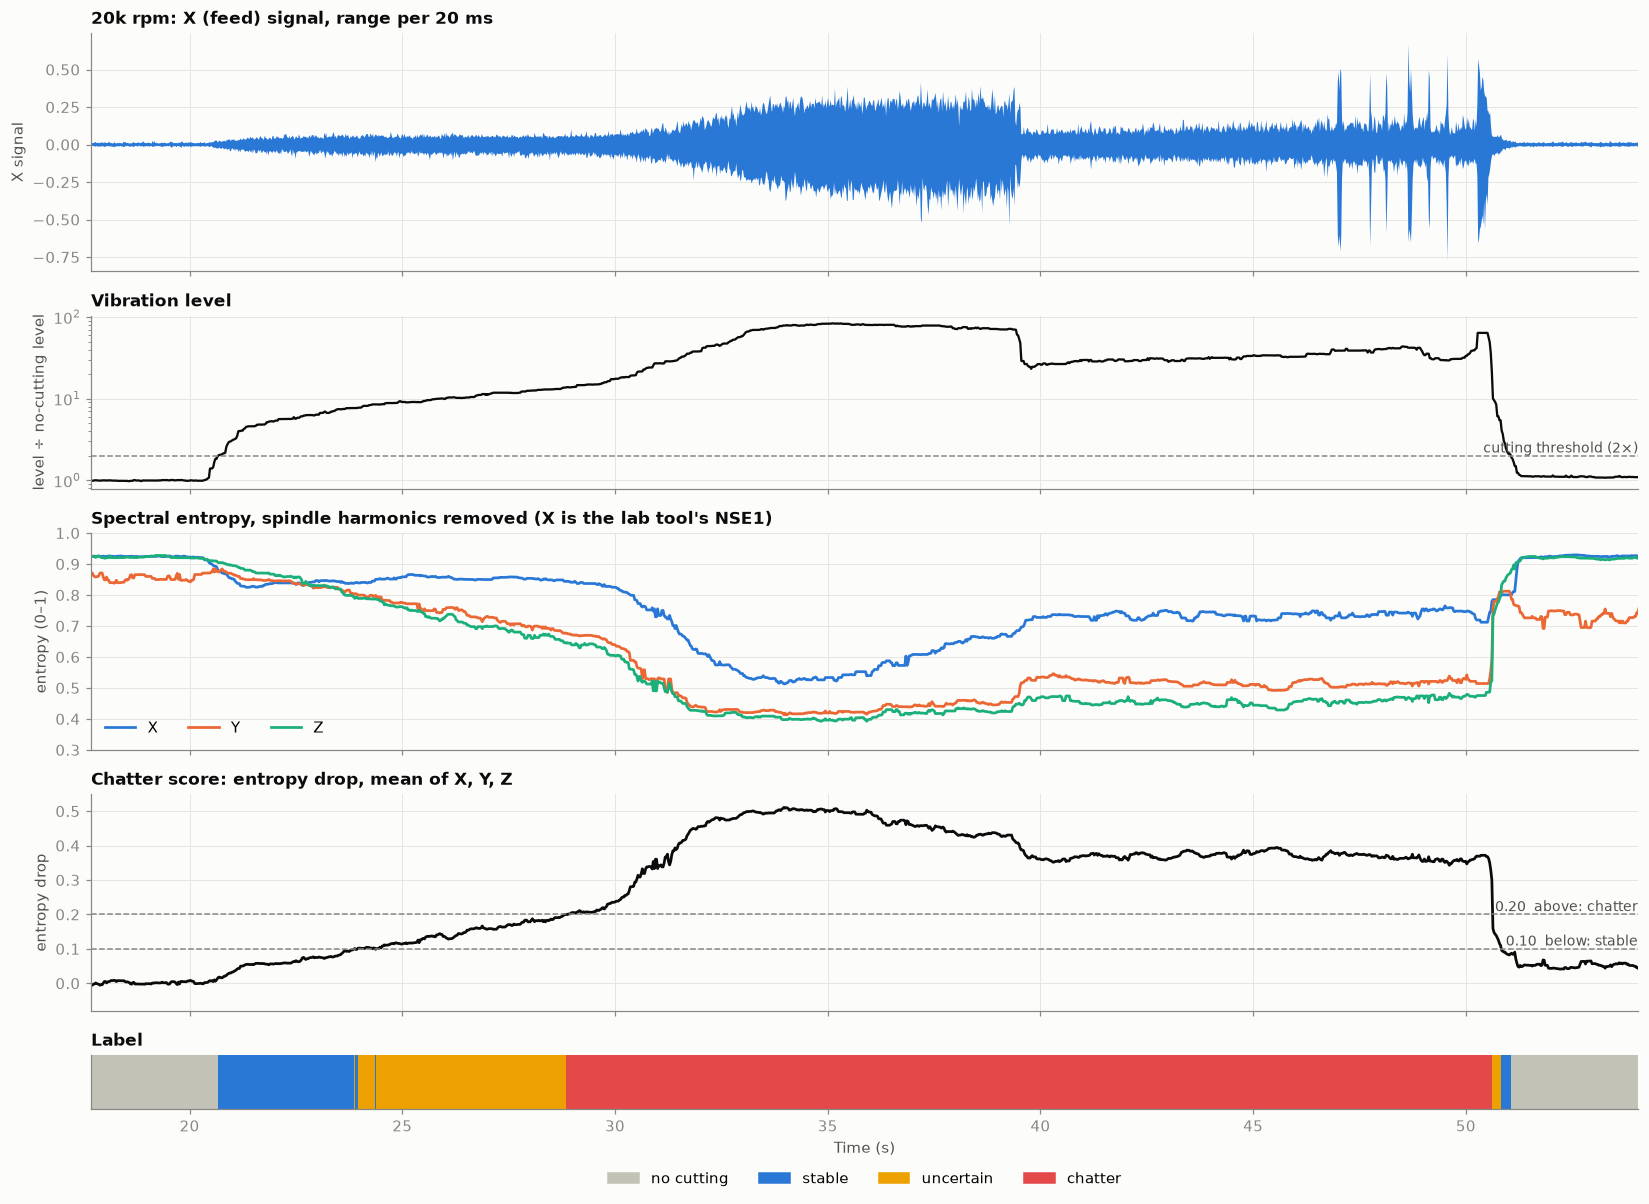

20k rpm: label segments (shorter than 0.15 s omitted)
     0.01 –  20.67 s   no cutting   20.66 s
    20.67 –  23.87 s   stable        3.20 s
    23.95 –  24.36 s   uncertain     0.41 s
    24.38 –  28.84 s   uncertain     4.45 s
    28.84 –  50.62 s   chatter      21.79 s
    50.62 –  50.83 s   uncertain     0.20 s
    50.83 –  51.06 s   stable        0.23 s
    51.06 –  59.97 s   no cutting    8.91 s


In [3]:
plot_run('20k')

## 2. 60k rpm

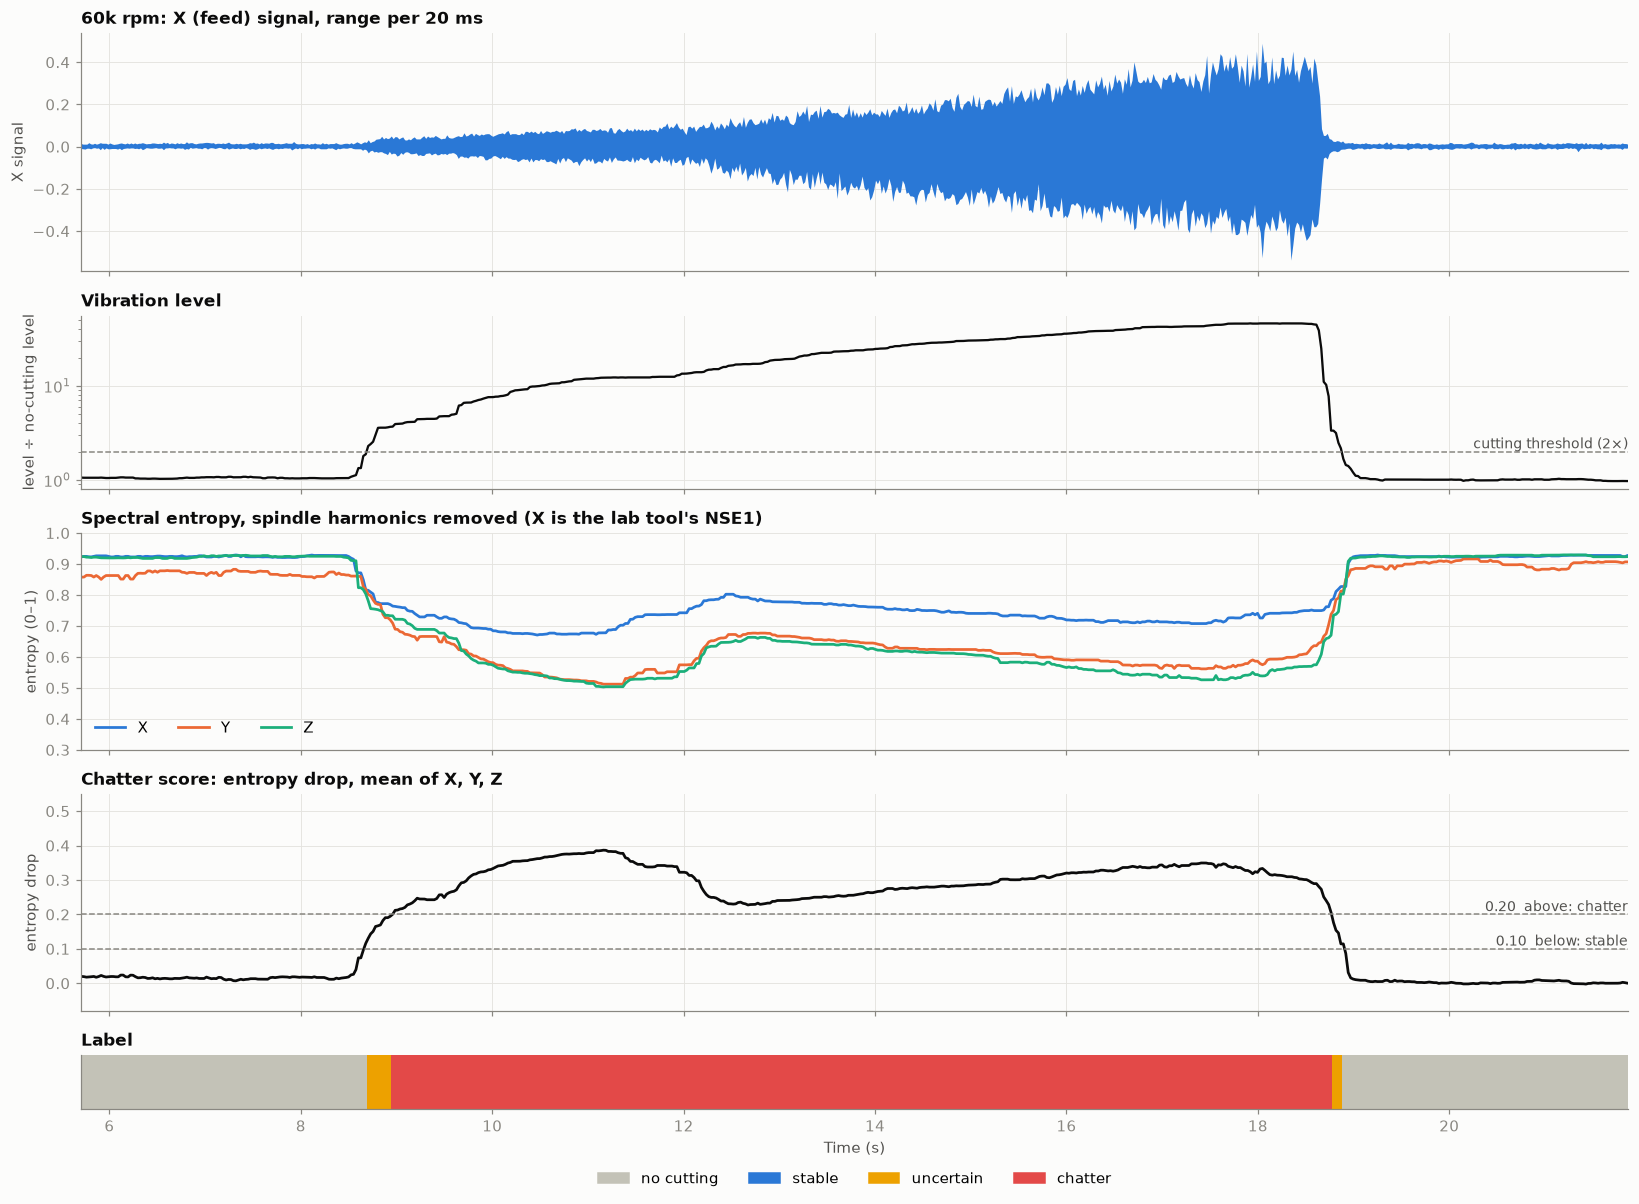

60k rpm: label segments (shorter than 0.15 s omitted)
     0.01 –   8.69 s   no cutting    8.68 s
     8.69 –   8.95 s   uncertain     0.26 s
     8.95 –  18.78 s   chatter       9.83 s
    18.88 –  25.48 s   no cutting    6.60 s


In [4]:
plot_run('60k')

## 3. 100k rpm

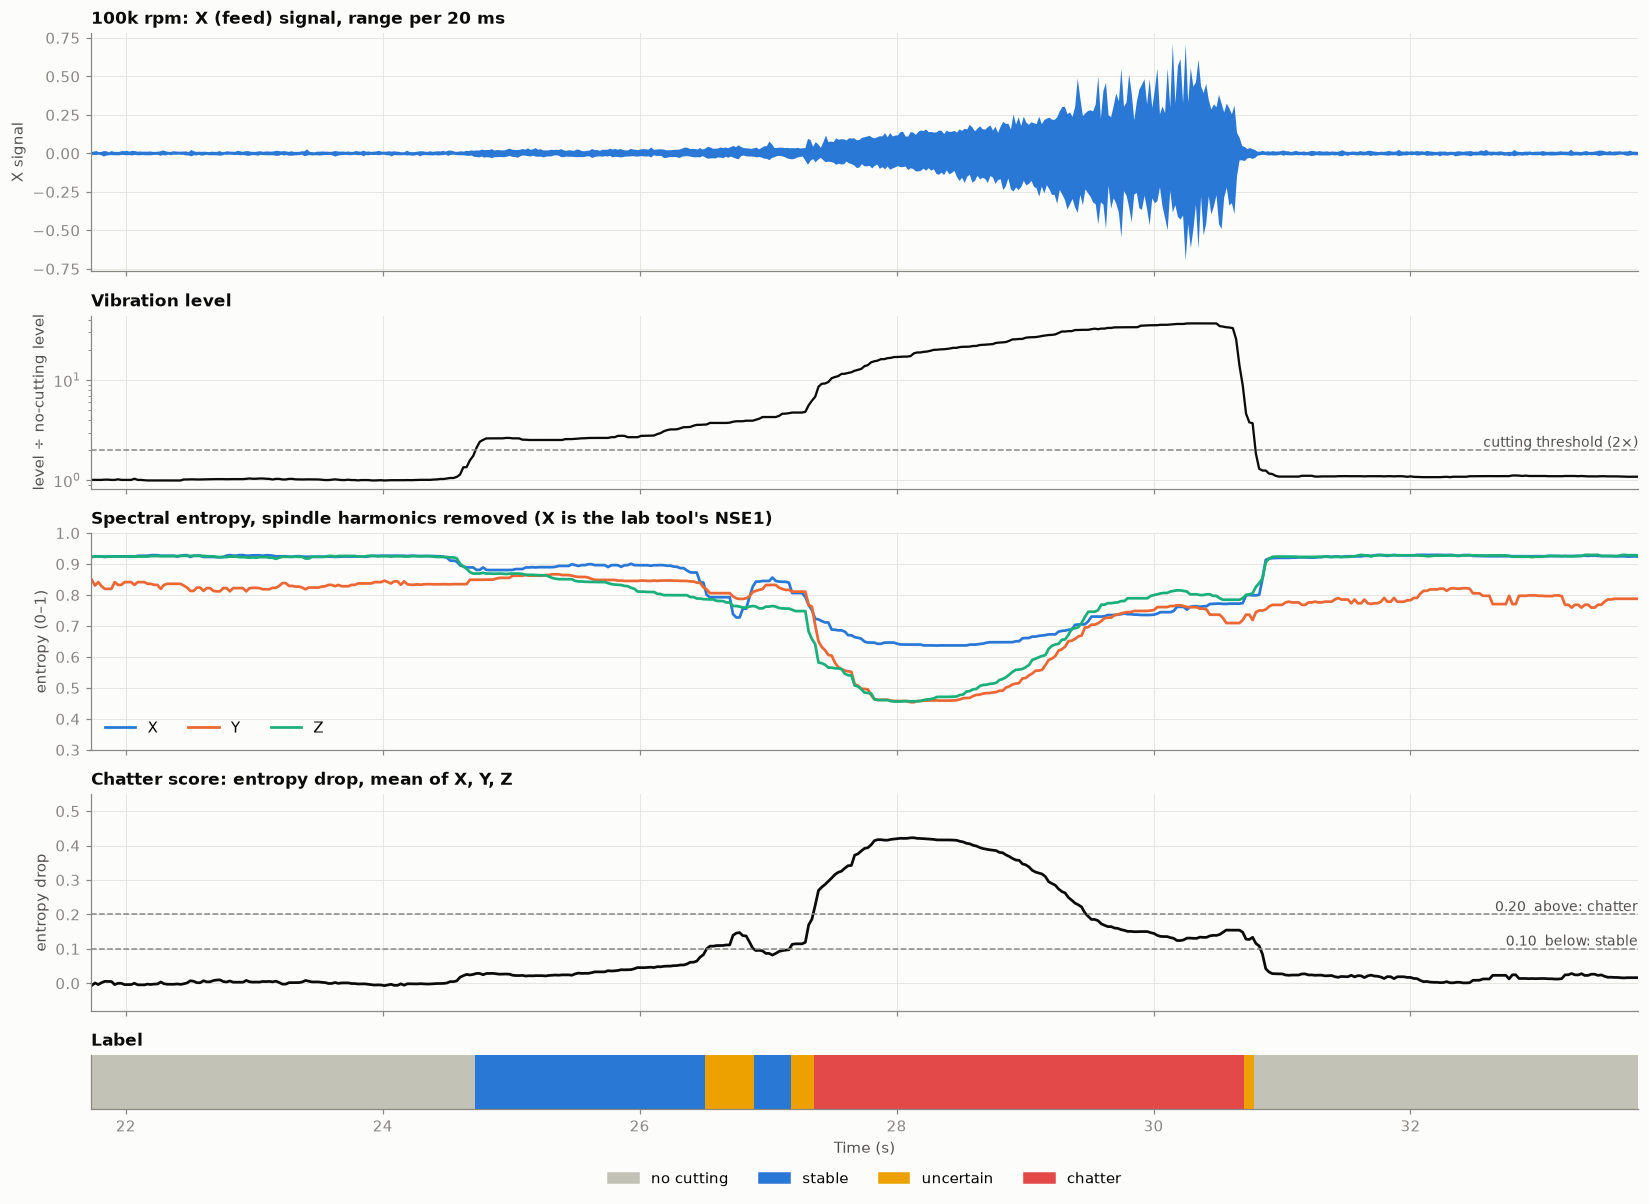

100k rpm: label segments (shorter than 0.15 s omitted)
     0.01 –  24.72 s   no cutting   24.70 s
    24.72 –  26.51 s   stable        1.79 s
    26.51 –  26.89 s   uncertain     0.38 s
    26.89 –  27.17 s   stable        0.28 s
    27.17 –  27.35 s   uncertain     0.18 s
    27.35 –  30.71 s   chatter       3.35 s
    30.78 –  36.24 s   no cutting    5.45 s


In [5]:
plot_run('100k')

## 4. How much of each label we have

   run   no cutting       stable    uncertain      chatter   by level rule
   20k       29.6 s        3.5 s        5.1 s       21.8 s           0.0 s
   60k       15.3 s        0.0 s        0.4 s        9.8 s           0.0 s
  100k       30.2 s        2.1 s        0.6 s        3.4 s           1.2 s
 total       75.0 s        5.6 s        6.1 s       35.0 s


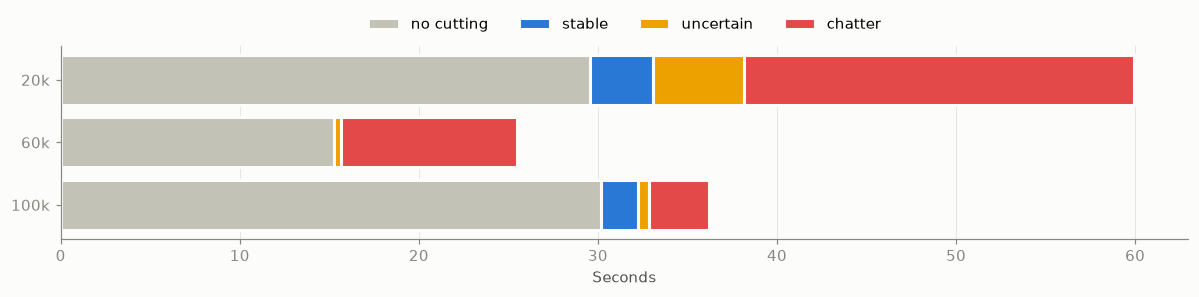

In [6]:
order = (lb.AIR, lb.STABLE, lb.UNCERTAIN, lb.CHATTER)
dur = {n: [float((L[n]['label'] == k).sum()*lb.HOP/FS) for k in order] for n in RUNS}
print(f"{'run':>6s}" + ''.join(f'{lb.NAMES[k]:>13s}' for k in order) + f"{'by level rule':>16s}")
for n in RUNS: print(f'{n:>6s}' + ''.join(f'{v:11.1f} s' for v in dur[n]) + f"{L[n]['by_level'].sum()*lb.HOP/FS:14.1f} s")
tot = np.sum(list(dur.values()), 0)
print(f"{'total':>6s}" + ''.join(f'{v:11.1f} s' for v in tot))
fig, ax = plt.subplots(figsize=(11, 2.8)); left = np.zeros(3); names = list(RUNS)
for j, k in enumerate(order):
    vals = np.array([dur[n][j] for n in names])
    ax.barh(names, vals, left=left, color=LABC[k], label=lb.NAMES[k], edgecolor='#fcfcfb', linewidth=2)
    left += vals
ax.invert_yaxis(); ax.set_xlabel('Seconds'); ax.grid(axis='y', visible=False); ax.legend(frameon=False, ncol=4, loc='lower center', bbox_to_anchor=(0.5, 1.0))
plt.tight_layout(); plt.savefig(FIG/'03_labels_balance.png', bbox_inches='tight'); plt.show()

## 5. Findings

**Labels per run**

| Run | No cutting | Stable | Uncertain | Chatter |
|---|---|---|---|---|
| 20k | 0–20.7 s and 51.1–60 s | 20.7–23.9 s | 23.9–28.8 s | 28.8–50.6 s |
| 60k | 0–8.7 s and 18.9–25.5 s | none | 8.7–8.9 s | 8.9–18.8 s |
| 100k | 0–24.7 s and 30.8–36.2 s | 24.7–27.2 s (with a short uncertain blip at 26.5–26.9 s) | 27.2–27.4 s | 27.4–30.7 s |

**What supports them (from the spectra of each stretch)**
- **100k, stable part:** 30–45 % of the energy sits exactly on spindle harmonics (1667 Hz and multiples). That is forced vibration from the cutter, the signature of a stable cut.
- **100k, chatter:** from 27.4 s the energy moves to 6577 Hz and 8245 Hz. They are not spindle harmonics, and they are 1668 Hz apart, which is the spindle frequency. A chatter frequency with spindle-frequency sidebands is the textbook pattern.
- **60k:** non-harmonic peaks from the first moment of the cut (5315 Hz, later 6787, 7788, 8787 Hz, spaced 1000 Hz = spindle frequency). There is no clear stable stretch in this run.
- **20k:** chatter peaks near 7.77 and 7.10 kHz (670 Hz apart, twice the spindle frequency), later 8.18 kHz.

**Agreement with the lab's LabVIEW plots**
- Our X-axis entropy reproduces the lab's NSE1 curve for the 20k and 100k runs: about 0.85 early in the cut, falling to 0.55–0.65 at 30.5 s (20k) and 27.5 s (100k), including the short dip near 26.7 s in the 100k run.
- The supplied 60k screenshot is of a different file (`Acce_60k_3_r2.lvm`, cut at 5.9–9.3 s). It cannot be compared with our `Acce_60k_1_r1.lvm`.
- NSE2 in the screenshots was not reproduced; its definition is not known to us.

**Where these labels are weak**
- **Thresholds are our choice.** 0.10 and 0.20 separate the three runs sensibly, but they are not the lab's values and are not validated against the machined surface.
- **Onset is gradual.** In the 20k run the Y and Z entropy starts falling at about 24 s, six seconds before X does. Using all three axes puts chatter onset at 28.8 s; the lab's X-only curve would put it near 30.5 s. The uncertain label covers this stretch.
- **Level rule.** 1.2 s at the end of the 100k cut (29.5–30.7 s) is labelled chatter by the level rule, not by entropy. The vibration there is the largest in the run but broadband.
- **Time resolution** is about 0.5 s because of the smoothing.
- **Very little stable cutting:** 5.6 s in total against 35 s of chatter, and none at 60k. A model cannot learn "stable" from this. New tests at conditions that stay stable are the most valuable data to record next.
- **Possible aliasing.** All chatter frequencies found are at 5–9 kHz, close to the 10 kHz limit of a 20 kHz recording.